#### Boostrap
- Bootstrap là kỹ thuật lấy mẫu ngẫu nhiên có hoàn lại (Sampling With Replacement) từ một tập dữ liệu gốc.
Nó được sử dụng trong Bagging và Random Forest.  
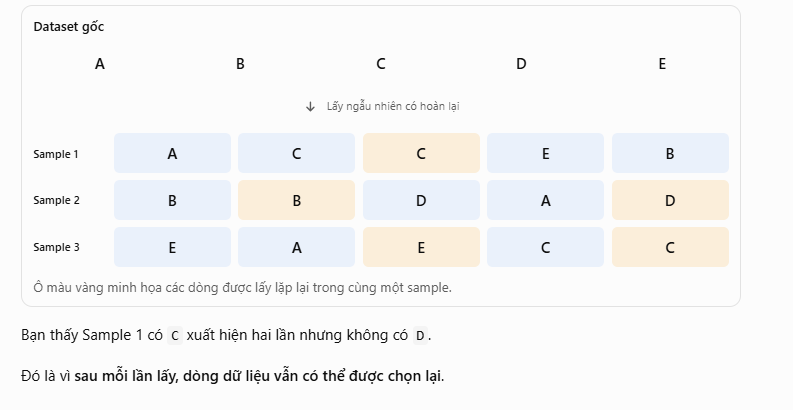

#### Bagging và Boosting

- Bagging và Boosting là hai kỹ thuật thuộc Ensemble Learning.
- Ý tưởng của Ensemble Learning là: Kết hợp nhiều mô hình (weak/base learners) để tạo ra một mô hình dự đoán tốt hơn.
- Điểm khác biệt lớn nhất:
  - Bagging: Các mô hình học tương đối độc lập, sau đó tổng hợp kết quả.
    - Mục tiêu chính: Giảm Variance, giúp mô hình ổn định hơn và hạn chế Overfitting.
      - Thường dùng với ramdonforest
  - Boosting: Các mô hình học tuần tự, mô hình sau tập trung cải thiện những điểm mô hình trước làm chưa tốt.
    - Mục tiêu: Xây dựng mô hình mạnh hơn từ nhiều mô hình yếu, thường giúp giảm Bias, nhưng cũng có thể ảnh hưởng đến Variance.
      - Thuật toán tiêu biểu: AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost.

| Tiêu chí | Bagging | Boosting |
| :--- | :--- | :--- |
| **Cách train** | Độc lập, có thể song song | Tuần tự |
| **Dữ liệu** | Các bootstrap samples | Điều chỉnh trọng số mẫu hoặc học phần lỗi còn lại |
| **Mục tiêu thường gặp** | Giảm Variance | Giảm Bias, tăng khả năng dự đoán |
| **Nhạy với nhiễu** | Thường ít hơn | Có thể nhạy hơn, tùy thuật toán |
| **Thuật toán** | Random Forest | AdaBoost, XGBoost |
| **Kết hợp** | Voting / Averaging | Weighted voting / Cộng các dự đoán |

### Random Forest
- là nhiều desion tree => rồi vote
- 2 cái vote: 
  - hard vote: là xem nhãn nào nhiều hơn vd [0,1,1,0,1,0,1] => 1
  - soft vote: tính theo trung bình xác suất: default của thuật toán trong sklearn vd: model [90,70,20]    => trung bình là 60 => dự đoán nhãn 1
trong sklearn dùng  
<pre>
from sklearn.ensemble import RandomForestClassifier
random_forest_classifier = RandomForestClassifier(random_state=0, n_estimators=5, max_depth=1)
random_forest_classifier.fit(features, labels)
random_forest_classifier.score(features, labels)
</pre>

### AdaBoost
- AdaBoost (Adaptive Boosting) là một thuật toán thuộc Ensemble Learning, sử dụng nhiều mô hình yếu (Weak Learners) để tạo thành một mô hình mạnh (Strong Learner).
- Ý tưởng quan trọng nhất:
    - Mỗi mô hình mới sẽ chú ý nhiều hơn đến những mẫu dữ liệu mà các mô hình trước dự đoán sai. Cuối cùng, kết hợp các mô hình bằng cách bỏ phiếu có trọng số.
    - ví dụ như cso 5 cái đoán 
      - 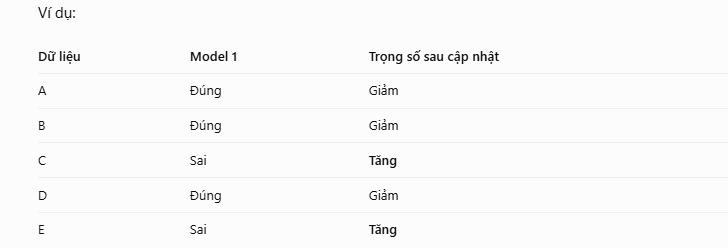
      - 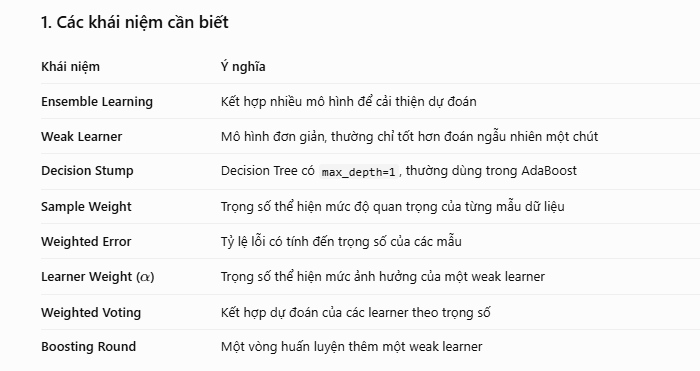


Decision Stump
Train: 0.6375
Test: 0.64
AdaBoost
Train: 0.965
Test: 0.95


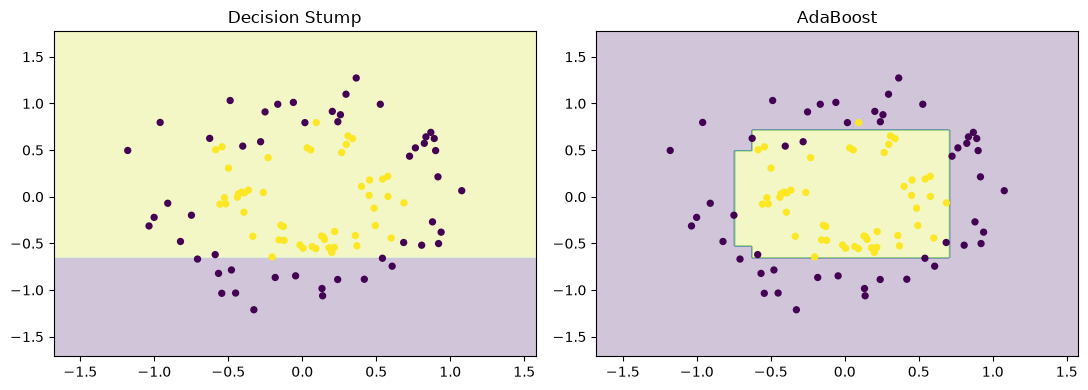

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score

# 1. Tạo dữ liệu
X, y = make_circles(
    n_samples=500,
    factor=0.5,
    noise=0.12,
    random_state=42
)

# 2. Chia train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Weak Learner
stump = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# 4. AdaBoost
"""   Hyperparameter	            Ý nghĩa
        estimator	            Weak learner được sử dụng
        n_estimators	        Số vòng boosting tối đa
        learning_rate	        Điều chỉnh mức đóng góp của từng learner
        max_depth	            Độ sâu cây trong weak learner
        random_state	        Tái lập kết quả khi có yếu tố ngẫu nhiên """
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# 5. Train
stump.fit(X_train, y_train)
ada.fit(X_train, y_train)

# 6. Evaluate
for name, model in [
    ("Decision Stump", stump),
    ("AdaBoost", ada)
]:
    print(name)
    print("Train:", accuracy_score(
        y_train, model.predict(X_train)
    ))
    print("Test:", accuracy_score(
        y_test, model.predict(X_test)
    ))

# 7. Vẽ Decision Boundary
def plot_boundary(ax, model, X, y, title):
    x_min, x_max = X[:, 0].min()-0.5, X[:, 0].max()+0.5
    y_min, y_max = X[:, 1].min()-0.5, X[:, 1].max()+0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25)
    ax.scatter(X[:, 0], X[:, 1], c=y, s=18)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

plot_boundary(axes[0], stump, X_test, y_test, "Decision Stump")
plot_boundary(axes[1], ada, X_test, y_test, "AdaBoost")

plt.tight_layout()
plt.show()


## Grandient Boost
- Gradient Boosting là một thuật toán thuộc Ensemble Learning, sử dụng nhiều Decision Trees được huấn luyện tuần tự, trong đó mỗi cây mới được thêm vào để giảm lỗi (Loss Function) của mô hình hiện tại.
- Gradient Boosting = Dự đoán → Tính lỗi → Train cây mới để sửa lỗi → Cộng vào dự đoán → Lặp lại.
  - 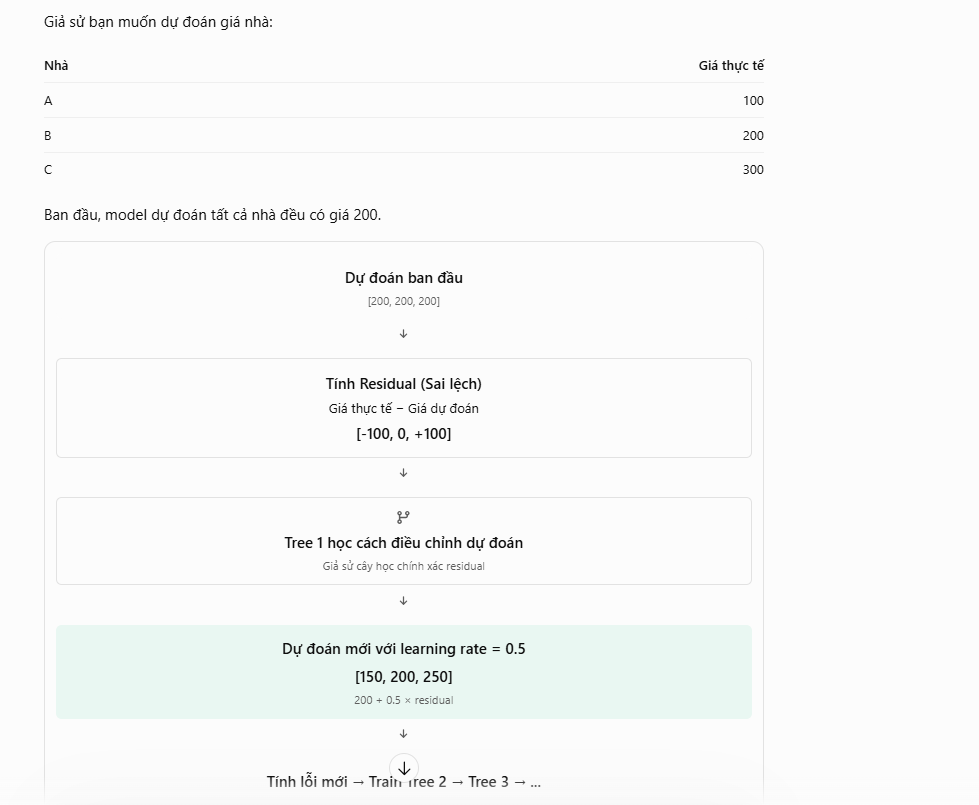
- Gradient Boosting cũng sử dụng ý tưởng đó, nhưng có một khác biệt:
  - Gradient Descent: Thường cập nhật các tham số của một model.
  - Gradient Boosting: Thêm một model mới (thường là Decision Tree) để cải thiện dự đoán tổng theo hướng giảm loss.

### XGBoost
- Nó kết hợp nhiều Decision Trees được huấn luyện tuần tự, trong đó mỗi cây mới được thêm vào để cải thiện dự đoán tổng của các cây trước.
Điểm khác biệt quan trọng với AdaBoost:
- AdaBoost: Tăng trọng số những mẫu mà model trước dự đoán sai.
- XGBoost: Thêm cây mới nhằm giảm Loss Function của toàn bộ mô hình, sử dụng gradient và đạo hàm bậc hai.
  - 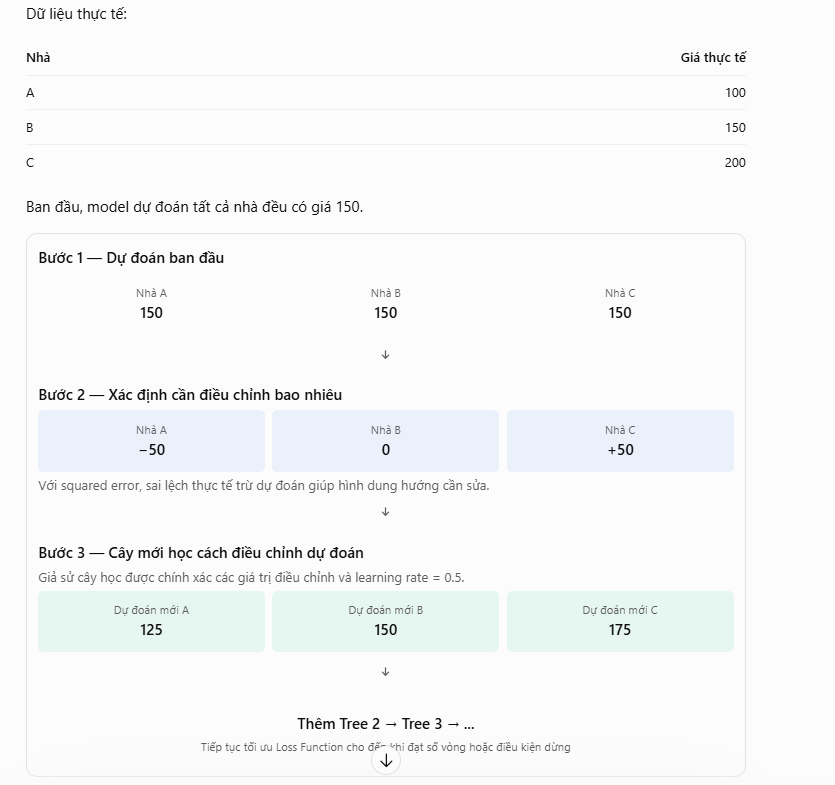

### So sánh Random Forest vs AdaBoost vs XGBoost
| Tiêu chí | Random Forest | AdaBoost | XGBoost |
| :--- | :--- | :--- | :--- |
| **Nhóm** | Bagging | Boosting | Gradient Boosting |
| **Cách train** | Độc lập | Tuần tự | Tuần tự |
| **Ý tưởng** | Nhiều cây cùng dự đoán | Tập trung vào mẫu sai | Giảm loss của dự đoán tổng |
| **Dữ liệu train** | Bootstrap samples | Dữ liệu có sample weights | Dữ liệu + gradient, Hessian |
| **Cây thường dùng** | Decision Tree | Decision Stump | Decision Tree |
| **Kết hợp** | Trung bình | Weighted Voting (phân loại) | Cộng đóng góp |
| **Mục tiêu nổi bật** | Giảm variance | Cải thiện các mẫu khó | Tối ưu loss có regularization |
| **Độ phức tạp** | Trung bình | Trung bình | Cao |
| **Hyperparameters** | Tương đối ít | Tương đối ít | Nhiều 
| **Độ nhạy với nhiễu** | Thường khá ổn định | Có thể nhạy | Phụ thuộc tuning   

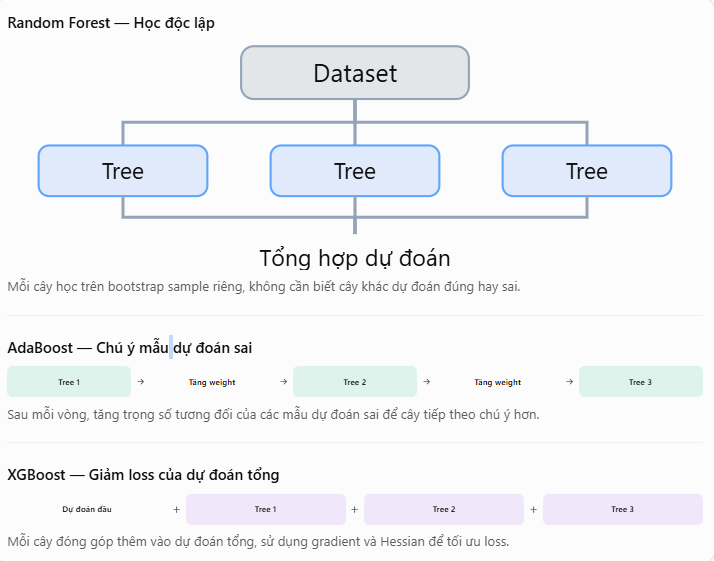

In [8]:

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier
)
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )
    test_acc = accuracy_score(
        y_test, model.predict(X_test)
    )

    print(f"{name}")
    print(f"Train accuracy: {train_acc:.4f}")
    print(f"Test accuracy:  {test_acc:.4f}")
    print("-" * 30)


Random Forest
Train accuracy: 1.0000
Test accuracy:  0.9500
------------------------------
AdaBoost
Train accuracy: 0.9575
Test accuracy:  0.9400
------------------------------
XGBoost
Train accuracy: 0.9950
Test accuracy:  0.9500
------------------------------


| Tình huống | Nên thử |
| :--- | :--- |
| **Cần baseline mạnh, dễ sử dụng** | Random Forest |
| **Muốn học cơ chế Boosting cơ bản** | AdaBoost |
| **Muốn tối ưu hiệu suất trên dữ liệu dạng bảng** | XGBoost |
| **Dataset có nhiều nhiễu** | Thử Random Forest trước |
| **Có thời gian tuning hyperparameters** | Thử XGBoost |